# Clusterización de clientes con K-Means
**Minería de Datos II – Examen Parcial II**

Objetivo: segmentar a los clientes de *Online Retail* con K-Means usando variables de comportamiento de compra (frecuencia, gasto, variedad, recencia, etc.).



In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from clusterizacion_clientes import preparar_clientes, AnalisisClusters

%matplotlib inline
pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams["figure.dpi"] = 100

## 1. Preparación de datos
`preparar_clientes()` limpia el CSV y resume **una fila por cliente** con 8 variables:
`Facturas`, `Productos`, `Cantidad`, `Gasto`, `PrecioProm`, `HoraProm`, `Inactividad` y `Ticket`.
Luego aplica `log1p` y `StandardScaler` para que clientes extremos no dominen la distancia euclidiana de K-Means.

In [4]:
datos_est, datos_num = preparar_clientes("2mil_online_retail.csv")
print(f"Clientes: {datos_num.shape[0]:,} | Variables: {datos_num.shape[1]}")
datos_num.head()

Clientes: 86 | Variables: 8


,Facturas,Productos,Cantidad,Gasto,PrecioProm,HoraProm,Inactividad,Ticket
CustomerID,,,,,,,,
"12,474.00",1,25,312,429.68,1.96,10.00,99,429.68
"12,678.00",1,35,2271,"3,243.13",2.21,13.00,253,"3,243.13"
"12,682.00",1,24,178,376.88,3.17,15.00,119,376.88
"12,748.00",3,18,87,208.59,4.12,12.67,6,69.53
"12,843.00",1,11,99,214.15,3.33,11.00,221,214.15


In [5]:
datos_num.describe().T

,count,mean,std,min,25%,50%,75%,max
Facturas,86.00,1.05,0.26,1.00,1.00,1.00,1.00,3.00
Productos,86.00,22.91,21.69,1.00,6.25,16.50,29.00,113.00
Cantidad,86.00,308.66,417.68,1.00,67.75,174.00,327.25,"2,271.00"
Gasto,86.00,488.07,621.84,2.95,158.50,307.28,432.55,"3,390.00"
PrecioProm,86.00,3.24,1.99,0.46,2.07,3.00,3.81,14.76
HoraProm,86.00,12.94,2.41,8.00,11.25,12.90,15.00,18.00
Inactividad,86.00,160.56,106.09,1.00,66.25,144.50,240.00,372.00
Ticket,86.00,471.99,609.55,2.95,146.48,307.28,428.26,"3,390.00"


**Datos estandarizados** (media ≈ 0 y desviación ≈ 1 por variable, después de `log1p`):

In [6]:
datos_est.describe().T[["mean", "std", "min", "max"]]

,mean,std,min,max
Facturas,-0.00,1.01,-0.18,7.08
Productos,0.00,1.01,-2.09,2.02
Cantidad,-0.00,1.01,-3.25,2.04
Gasto,-0.00,1.01,-3.95,2.28
PrecioProm,-0.00,1.01,-2.53,3.59
HoraProm,0.00,1.01,-2.42,1.86
Inactividad,-0.00,1.01,-4.16,1.19
Ticket,0.00,1.01,-3.94,2.32


## 2. Elección del número de clusters (*k*)
Se evalúan *k* = 2 … 8 con dos criterios:
- **Codo:** inercia (suma de distancias al centroide); se busca el punto donde deja de bajar rápido.
- **Silueta:** qué tan separados están los clusters (más cerca de 1 es mejor).

In [7]:
analisis = AnalisisClusters(datos_est, datos_num, n_clusters=3)
tabla_k = analisis.elegir_k(k_max=8)
tabla_k

C:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than availabl

,inercia,silueta
k,,
2,515.11,0.23
3,429.77,0.25
4,375.43,0.21
5,329.22,0.19
6,289.59,0.20
7,259.27,0.21
8,235.25,0.21


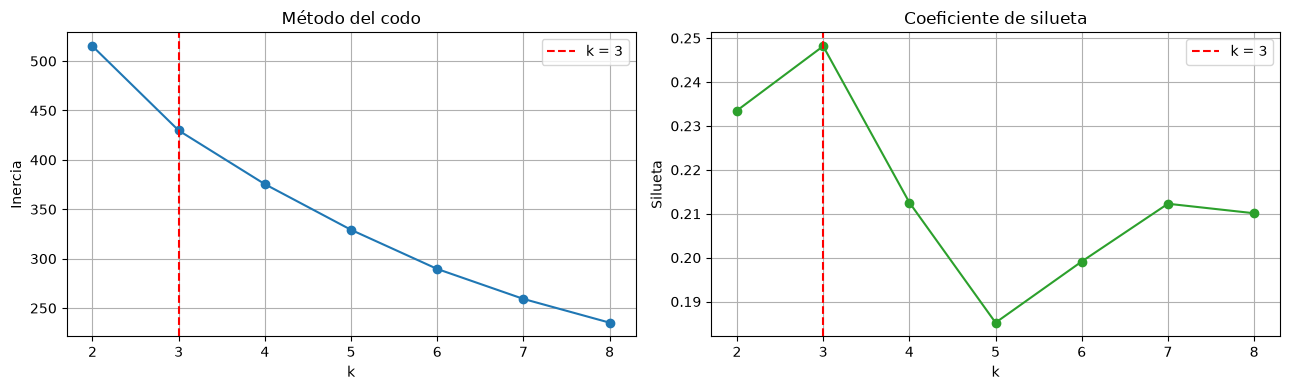

k con mayor silueta: 3


In [8]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
analisis._codo(axs[0], tabla_k)
analisis._silueta(axs[1], tabla_k)
plt.tight_layout()
plt.show()

print("k con mayor silueta:", tabla_k["silueta"].idxmax())

## 3. Ajuste del modelo K-Means
El K-Means se entrena con **todas** las variables estandarizadas. El ACP se usa solo para poder dibujar los clusters en 2D.

In [9]:
K = 3   # <- cambia aquí si tu análisis de la sección 2 indica otro valor

analisis = AnalisisClusters(datos_est, datos_num, n_clusters=K).ajustar()
print(f"Coeficiente de silueta (k={K}): {analisis.silueta:.3f}")

C:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


Coeficiente de silueta (k=3): 0.248


In [10]:
tamanos = analisis.df["cluster"].value_counts().sort_index()
resumen_tam = pd.DataFrame({"Clientes": tamanos, "Porcentaje": tamanos / tamanos.sum() * 100})
resumen_tam

,Clientes,Porcentaje
cluster,,
0,33,38.37
1,50,58.14
2,3,3.49


## 4. Visualización
Figura completa: codo, silueta, clusters en 2D (ACP), radar y barras.

C:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than availabl

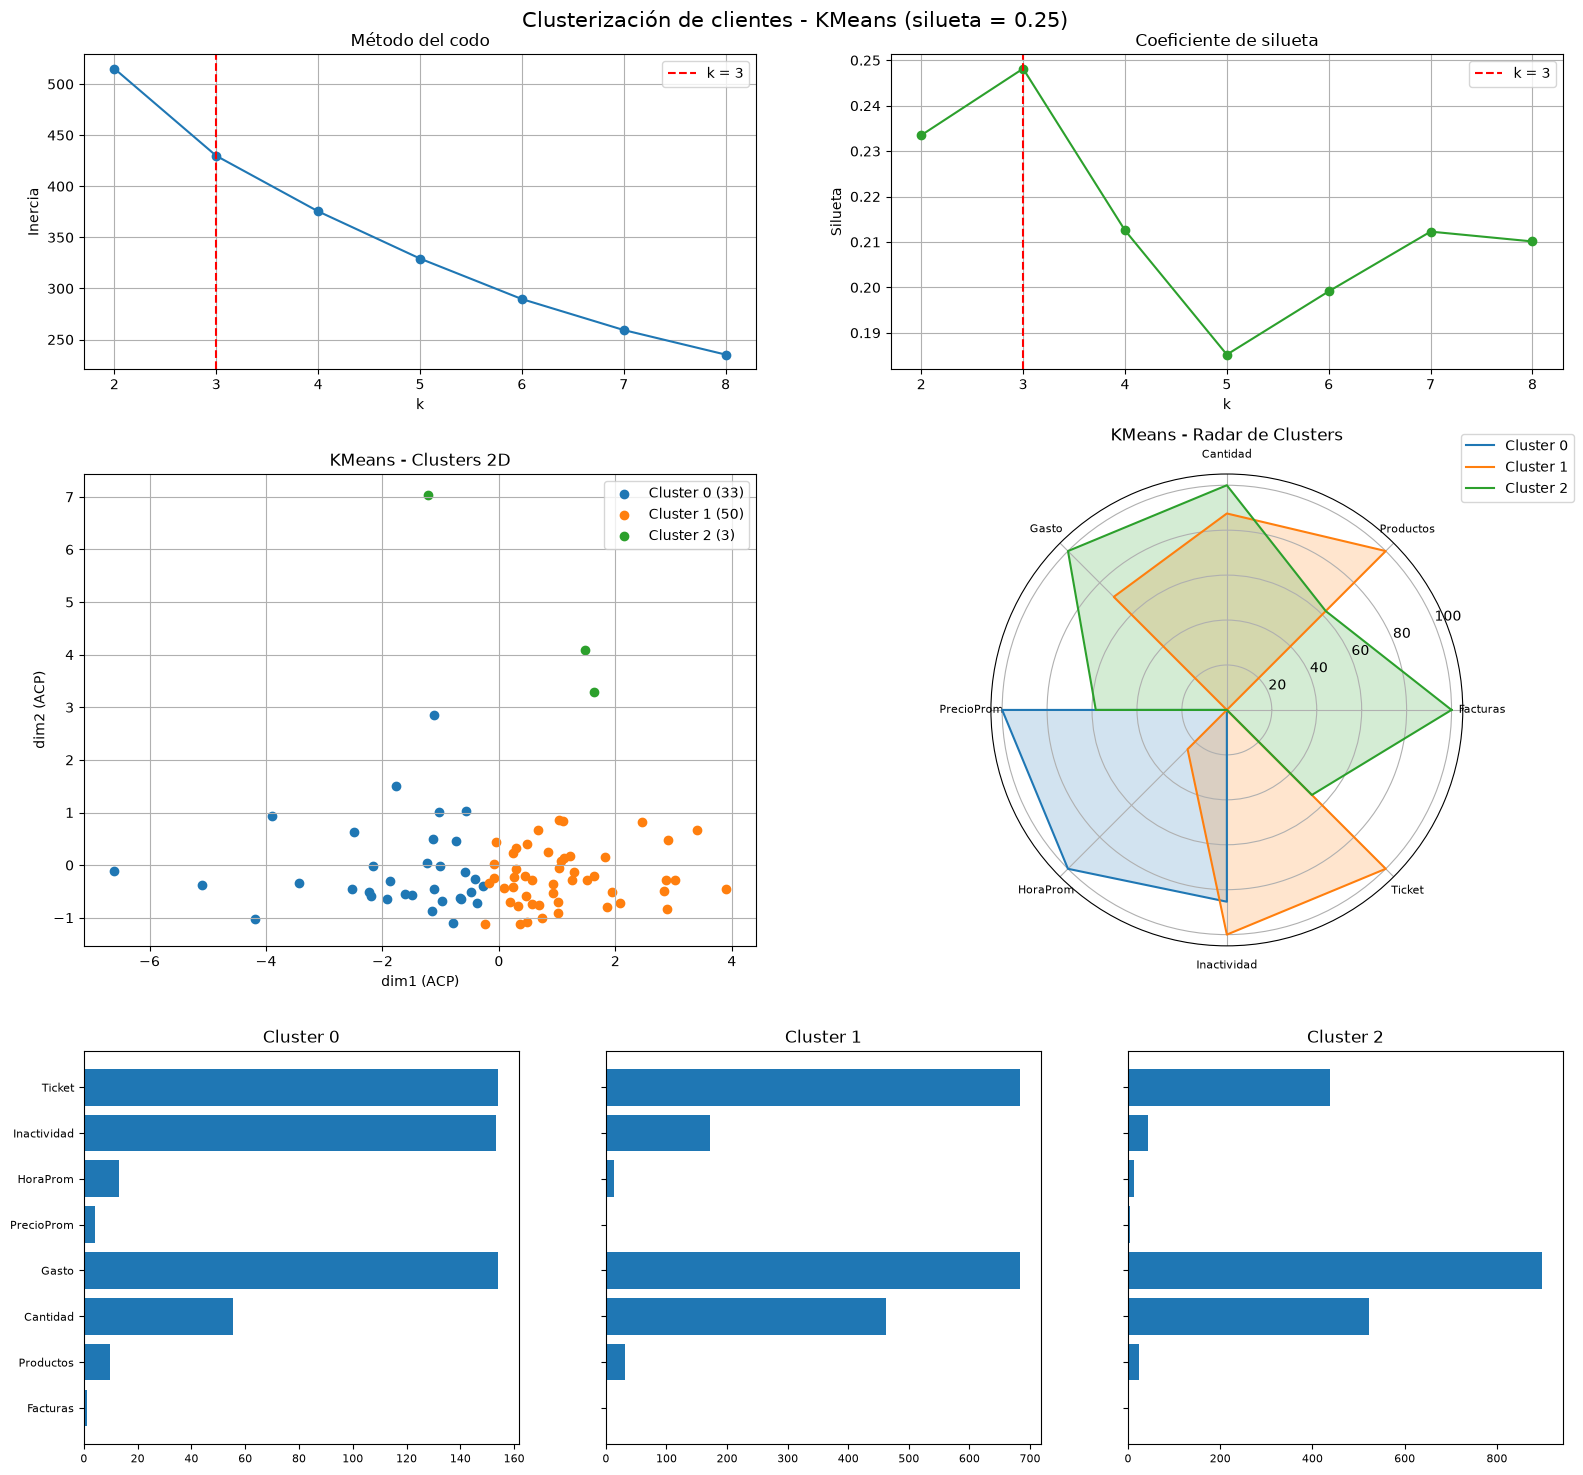

In [11]:
analisis.graficar(k_max=8)

### Varianza explicada por el ACP
Qué tan bien representa el plano 2D a los datos originales (solo afecta al gráfico, no al clustering).

In [12]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2).fit(datos_est)
print(f"dim1: {pca.explained_variance_ratio_[0]:.1%} | dim2: {pca.explained_variance_ratio_[1]:.1%} "
      f"| total: {pca.explained_variance_ratio_.sum():.1%}")

dim1: 42.0% | dim2: 16.8% | total: 58.8%


## 5. Perfil de cada cluster
Promedio de cada variable **en su escala original** (por eso se calcula sobre `datos_num`).

In [13]:
perfil = pd.DataFrame(
    analisis.centros,
    columns=datos_num.columns,
    index=[f"Cluster {i}" for i in range(K)],
)
perfil["Clientes"] = tamanos.values
perfil

,Facturas,Productos,Cantidad,Gasto,PrecioProm,HoraProm,Inactividad,Ticket,Clientes
Cluster 0,1.00,9.61,55.33,154.07,4.20,13.15,153.39,154.07,33
Cluster 1,1.00,31.66,463.08,683.88,2.59,12.82,172.34,683.88,50
Cluster 2,2.33,23.33,521.67,898.40,3.53,12.71,43.00,437.61,3


Para comparar entre clusters, cuánto se aleja cada promedio del **promedio global** (en %). Valores positivos = por encima del promedio.

In [14]:
global_mean = datos_num.mean()
desviacion = (perfil[datos_num.columns] / global_mean - 1) * 100

desviacion.style.format("{:+.0f}%").background_gradient(cmap="RdBu_r", axis=None, vmin=-100, vmax=100)

,Facturas,Productos,Cantidad,Gasto,PrecioProm,HoraProm,Inactividad,Ticket
Cluster 0,-4%,-58%,-82%,-68%,+30%,+2%,-4%,-67%
Cluster 1,-4%,+38%,+50%,+40%,-20%,-1%,+7%,+45%
Cluster 2,+123%,+2%,+69%,+84%,+9%,-2%,-73%,-7%


## 6. Interpretación de los segmentos
_Con las tablas y el radar de arriba, describe cada cluster y ponle un nombre de negocio. Ejemplo de estructura:_

| Cluster | Nombre sugerido | Características | Acción recomendada |
|---|---|---|---|
| 0 | _(ej. Clientes ocasionales)_ | _(pocas facturas, gasto bajo, alta inactividad)_ | _(campañas de reactivación)_ |
| 1 | _(ej. Clientes fieles)_ | _(muchas facturas, gasto alto, baja inactividad)_ | _(programa de lealtad)_ |
| 2 | _(ej. ...)_ | | |

In [15]:
# Guardar la asignación de cluster por cliente
resultado = datos_num.copy()
resultado["Cluster"] = analisis.df["cluster"]
resultado.to_csv("clientes_con_cluster.csv")
resultado.head()

,Facturas,Productos,Cantidad,Gasto,PrecioProm,HoraProm,Inactividad,Ticket,Cluster
CustomerID,,,,,,,,,
"12,474.00",1,25,312,429.68,1.96,10.00,99,429.68,1
"12,678.00",1,35,2271,"3,243.13",2.21,13.00,253,"3,243.13",1
"12,682.00",1,24,178,376.88,3.17,15.00,119,376.88,1
"12,748.00",3,18,87,208.59,4.12,12.67,6,69.53,2
"12,843.00",1,11,99,214.15,3.33,11.00,221,214.15,0
